In [2]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


ModuleNotFoundError: No module named 'dotenv'

In [ ]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
train_data_dir = os.path.join(dataset_path, "data02", "train")
test_data_dir = os.path.join(dataset_path, "data02", "test")
val_data_dir = os.path.join(dataset_path, "data02", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data02/train
/Users/joshan/Documents/final-year-project/dataset/data02/test
/Users/joshan/Documents/final-year-project/dataset/data02/val


In [25]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 11873 files belonging to 3 classes.
Found 1392 files belonging to 3 classes.
Found 694 files belonging to 3 classes.


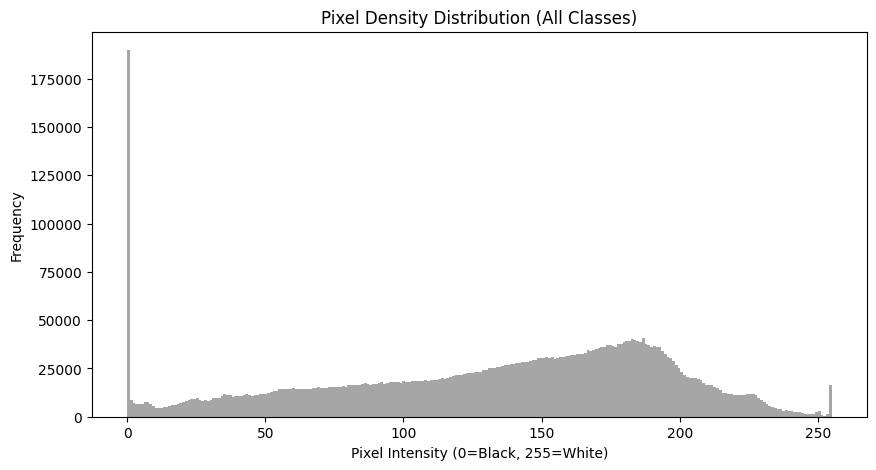

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch (e.g., 32 images)
for images, labels in train_ds.take(1):
    # Flatten all pixels in the batch into a 1D array
    pixels = images.numpy().flatten()
    
    plt.figure(figsize=(10, 5))
    plt.hist(pixels, bins=256, color='gray', alpha=0.7)
    plt.title('Pixel Density Distribution (All Classes)')
    plt.xlabel('Pixel Intensity (0=Black, 255=White)')
    plt.ylabel('Frequency')
    plt.show()

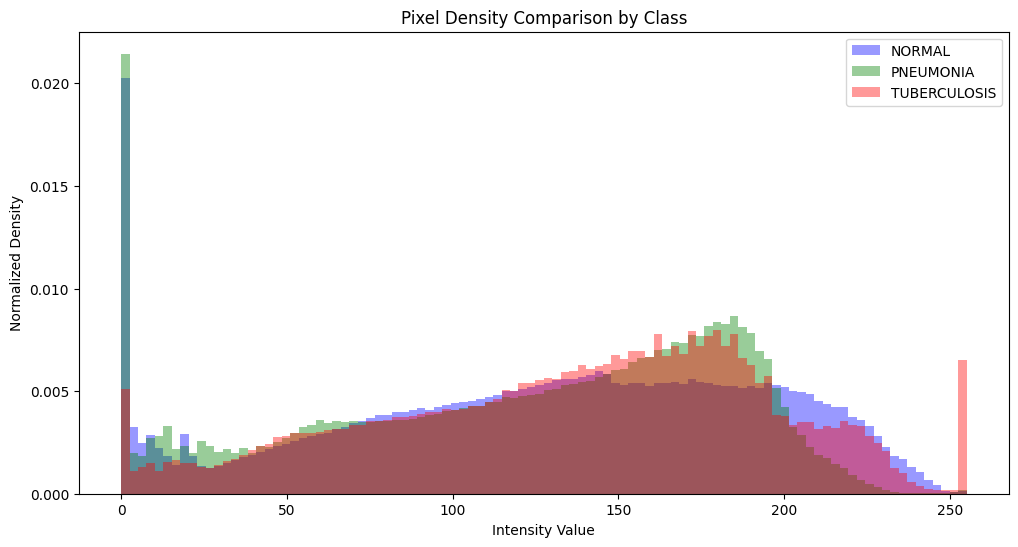

In [27]:
def plot_class_histograms(dataset, class_names):
    plt.figure(figsize=(12, 6))
    
    # Store pixels for each class
    class_pixels = {name: [] for name in class_names}
    
    # Analyze 5 batches for a good sample size
    for images, labels in dataset.take(5):
        images = images.numpy()
        labels = np.argmax(labels.numpy(), axis=1)
        
        for i in range(len(images)):
            cls_name = class_names[labels[i]]
            # Add flattened pixels of this specific image
            class_pixels[cls_name].extend(images[i].flatten())

    # Plotting
    colors = ['blue', 'green', 'red']
    for i, name in enumerate(class_names):
        plt.hist(class_pixels[name], bins=100, alpha=0.4, 
                 label=name, color=colors[i], density=True)

    plt.title('Pixel Density Comparison by Class')
    plt.xlabel('Intensity Value')
    plt.ylabel('Normalized Density')
    plt.legend()
    plt.show()

# Usage
plot_class_histograms(train_ds, train_ds.class_names)

In [28]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(3, activation='softmax') # Softmax for multi-class probability
])

In [29]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 161s 430ms/step - accuracy: 0.8261 - loss: 0.4361 - val_accuracy: 0.8977 - val_loss: 0.2686
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 160s 431ms/step - accuracy: 0.9081 - loss: 0.2341 - val_accuracy: 0.9121 - val_loss: 0.2088
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 152s 409ms/step - accuracy: 0.9293 - loss: 0.1872 - val_accuracy: 0.9452 - val_loss: 0.1485
Epoch 4/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 158s 424ms/step - accuracy: 0.9381 - loss: 0.1627 - val_accuracy: 0.9452 - val_loss: 0.1382
Epoch 5/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 159s 428ms/step - accuracy: 0.9520 - loss: 0.1314 - val_accuracy: 0.9524 - val_loss: 0.1458
Epoch 6/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 165s 443ms/step - accuracy: 0.9598 - loss: 0.1075 - val_accuracy: 0.9510 - val_loss: 0.1407
Epoch 7/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 158s 423ms/step - accuracy: 0.9661 - loss: 0.0900 - val_accuracy: 0.9452 - val_loss: 0.1506
Epoch 8/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 168s 450ms/step - accuracy: 0.9698 -

In [30]:
# Save the model
model.save('chest_xray_classifier.keras')
print("Model saved successfully!")

Model saved successfully!


In [31]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

44/44 ━━━━━━━━━━━━━━━━━━━━ 7s 145ms/step - accuracy: 0.9188 - loss: 0.2026
Test Loss: 0.202615886926651
Test Accuracy: 91.88%


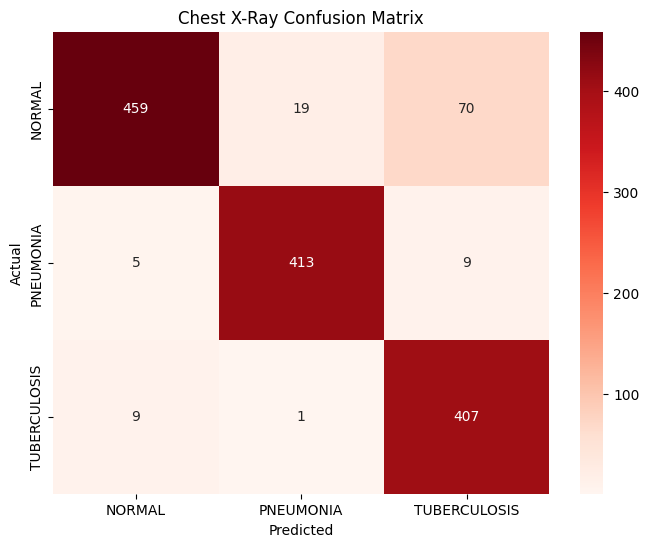

              precision    recall  f1-score   support

      NORMAL       0.97      0.84      0.90       548
   PNEUMONIA       0.95      0.97      0.96       427
TUBERCULOSIS       0.84      0.98      0.90       417

    accuracy                           0.92      1392
   macro avg       0.92      0.93      0.92      1392
weighted avg       0.93      0.92      0.92      1392



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))